# End-to-End Sales Forecasting & Demand Intelligence System

##**XYLOFY AI Internship – Week 3 & Week 4 Final Project**
### Submitted By:
**Roshan Manjal**

### Project Overview
This project focuses on building an intelligent sales forecasting and demand intelligence system using historical sales data. The objective is to forecast future sales, detect anomalies, segment products based on demand patterns, and provide business recommendations through an interactive dashboard.

# Task 1: Data Loading, Merging and Deep Exploration

### Objective
The objective of this task is to load the sales dataset, perform initial data exploration, create time-based features, identify data quality issues, and generate business insights regarding revenue, regions, shipping performance, and seasonality.

## Importing Required Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

## Loading the Dataset

In [2]:
df = pd.read_csv('train.csv')

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12-06-2017,16-06-2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


## Understanding the Dataset Structure

In [3]:
print("Dataset Shape:", df.shape)

df.info()

Dataset Shape: (9800, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-nu

In [4]:
df.describe()

,Row ID,Postal Code,Sales
count,9800.000000,9789.000000,9800.000000
mean,4900.500000,55273.322403,230.769059
std,2829.160653,32041.223413,626.651875
min,1.000000,1040.000000,0.444000
25%,2450.750000,23223.000000,17.248000
50%,4900.500000,58103.000000,54.490000
75%,7350.250000,90008.000000,210.605000
max,9800.000000,99301.000000,22638.480000


### Observation

The dataset contains sales transactions across multiple years, categories, sub-categories, regions, and customer segments. It will be used for sales forecasting, anomaly detection, and demand intelligence analysis.

## Data Type Conversion

In [5]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales'],
      dtype='object')

## Converting Date Columns and Creating Time Features

In [6]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    dayfirst=True
)

df['Ship Date'] = pd.to_datetime(
    df['Ship Date'],
    dayfirst=True
)

df[['Order Date','Ship Date']].head()

,Order Date,Ship Date
0,2017-11-08,2017-11-11
1,2017-11-08,2017-11-11
2,2017-06-12,2017-06-16
3,2016-10-11,2016-10-18
4,2016-10-11,2016-10-18


In [7]:
df['Year'] = df['Order Date'].dt.year

df['Month'] = df['Order Date'].dt.month

df['Week'] = df['Order Date'].dt.isocalendar().week

df['DayOfWeek'] = df['Order Date'].dt.day_name()

df['Quarter'] = df['Order Date'].dt.quarter

In [8]:
def get_season(month):

    if month in [12,1,2]:
        return "Winter"

    elif month in [3,4,5]:
        return "Spring"

    elif month in [6,7,8]:
        return "Summer"

    else:
        return "Autumn"

df['Season'] = df['Month'].apply(get_season)

In [9]:
df[['Year','Month','Week','DayOfWeek','Quarter','Season']].head()

,Year,Month,Week,DayOfWeek,Quarter,Season
0,2017,11,45,Wednesday,4,Autumn
1,2017,11,45,Wednesday,4,Autumn
2,2017,6,24,Monday,2,Summer
3,2016,10,41,Tuesday,4,Autumn
4,2016,10,41,Tuesday,4,Autumn


In [10]:
print("Min Date:", df['Order Date'].min())
print("Max Date:", df['Order Date'].max())

Min Date: 2015-01-03 00:00:00
Max Date: 2018-12-30 00:00:00


## Data Quality Checks

In [11]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [12]:
df.duplicated().sum()

np.int64(0)

### Observation

The dataset is generally clean and suitable for analysis. Only 11 missing values were found in the Postal Code column, which is not critical for sales forecasting. No duplicate records were detected in the dataset.

## Shipping Time Analysis

In [13]:
df['ShippingDays'] = (
    df['Ship Date'] -
    df['Order Date']
).dt.days

df['ShippingDays'].describe()

,ShippingDays
count,9800.000000
mean,3.961122
std,1.749614
min,0.000000
25%,3.000000
50%,4.000000
75%,5.000000
max,7.000000


In [14]:
avg_shipping = df['ShippingDays'].mean()

print("Average Shipping Time:", round(avg_shipping,2), "days")

Average Shipping Time: 3.96 days


### Observation

Shipping time was calculated as the difference between Ship Date and Order Date. The average shipping duration provides insight into operational efficiency and delivery performance.

## Shipping Time by Region

In [15]:
shipping_region = (
    df.groupby('Region')['ShippingDays']
      .mean()
      .sort_values()
)

shipping_region

,ShippingDays
Region,
East,3.910233
West,3.930255
South,3.961202
Central,4.065876


In [16]:
import os

In [17]:
os.makedirs("charts", exist_ok=True)

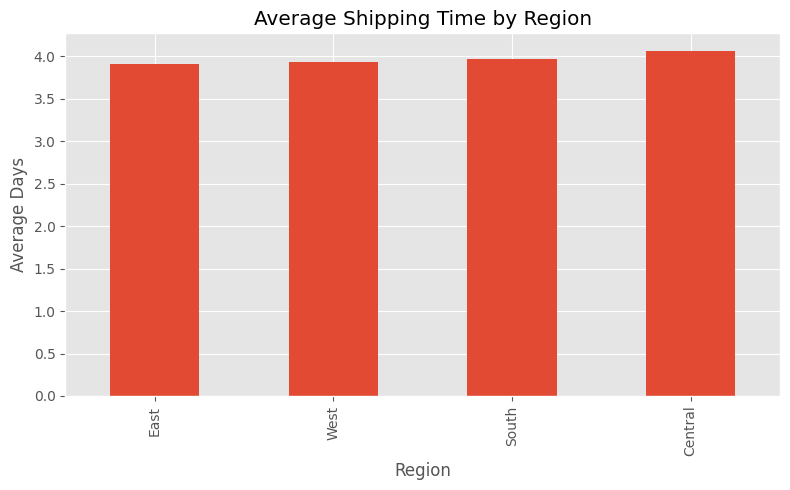

In [18]:
plt.figure(figsize=(8,5))

shipping_region.plot(kind='bar')

plt.title("Average Shipping Time by Region")

plt.xlabel("Region")

plt.ylabel("Average Days")

plt.tight_layout()

plt.savefig("charts/shipping_time_region.png")

plt.show()

### Observation

The average shipping time is approximately 3.96 days, with most orders being delivered within 3 to 5 days. The maximum shipping time observed is 7 days, indicating relatively efficient order fulfillment and delivery operations across the dataset.

### Observation

Regional shipping performance varies across different regions. Regions with lower average shipping times demonstrate more efficient delivery operations compared to regions with higher shipping durations.

## Revenue Analysis by Product Category

In [19]:
category_sales = (
    df.groupby('Category')['Sales']
      .sum()
      .sort_values(ascending=False)
)

category_sales

,Sales
Category,
Technology,827455.8730
Furniture,728658.5757
Office Supplies,705422.3340


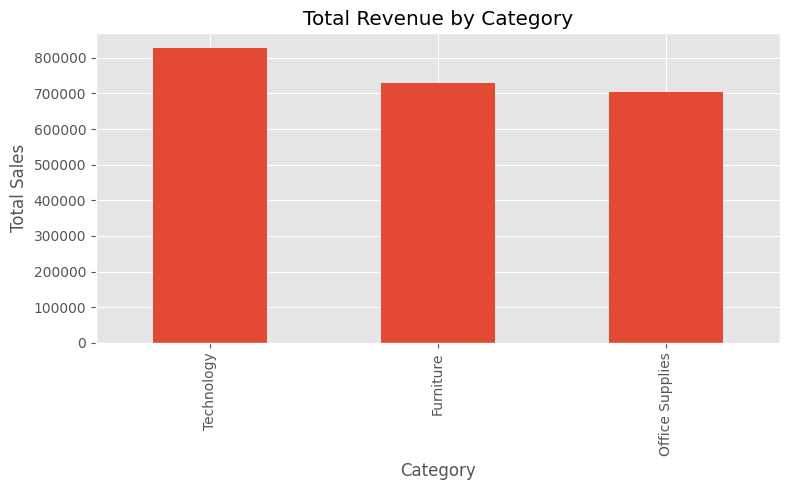

In [20]:
plt.figure(figsize=(8,5))

category_sales.plot(kind='bar')

plt.title('Total Revenue by Category')

plt.xlabel('Category')

plt.ylabel('Total Sales')

plt.tight_layout()

plt.savefig('charts/category_revenue.png')

plt.show()

### Observation

Technology generated the highest total revenue of approximately $827,456, followed by Furniture with $728,659 and Office Supplies with $705,422. Although all three categories contribute significantly to overall sales, Technology remains the strongest revenue-generating category.

### Business Insight

The Technology category is the primary revenue driver for the business. Increasing inventory availability, marketing efforts, and customer engagement within this category could potentially generate higher future sales and profitability.

## Regional Sales Growth Analysis

In [21]:
region_year_sales = (
    df.groupby(['Year','Region'])['Sales']
      .sum()
      .reset_index()
)

region_year_sales.head()

,Year,Region,Sales
0,2015,Central,102920.5206
1,2015,East,127652.8190
2,2015,South,103374.9055
3,2015,West,145907.9630
4,2016,Central,102425.1724


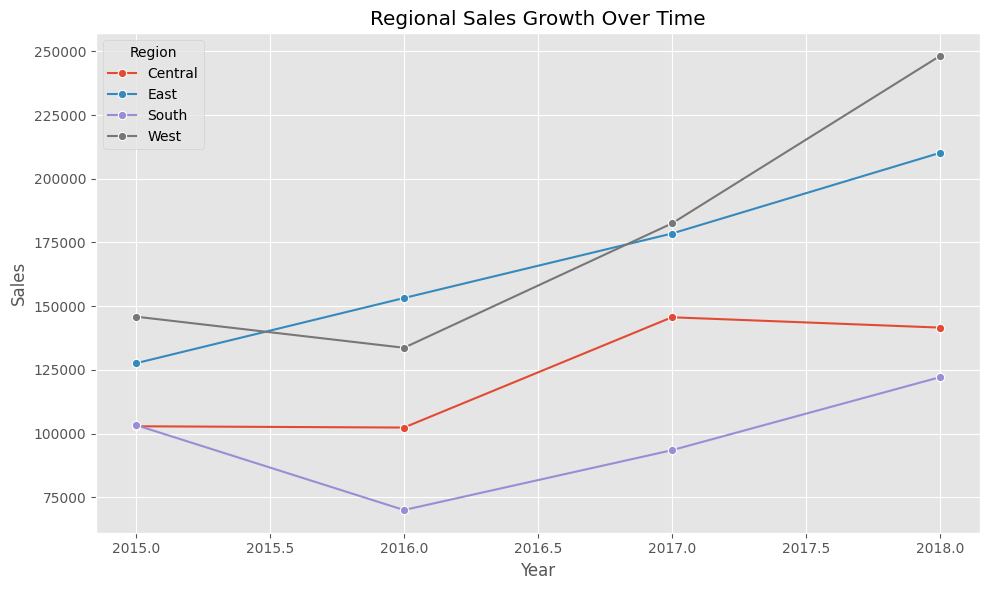

In [22]:
plt.figure(figsize=(10,6))

sns.lineplot(
    data=region_year_sales,
    x='Year',
    y='Sales',
    hue='Region',
    marker='o'
)

plt.title('Regional Sales Growth Over Time')

plt.tight_layout()

plt.savefig('charts/regional_growth.png')

plt.show()

In [23]:
region_year_sales.pivot(
    index='Year',
    columns='Region',
    values='Sales'
)

Region,Central,East,South,West
Year,,,,
2015,102920.5206,127652.819,103374.9055,145907.9630
2016,102425.1724,153225.183,70076.0825,133709.5675
2017,145673.8800,178511.538,93535.9035,182471.2285
2018,141627.3402,210129.186,122164.5675,248130.9255


West Region shows the strongest and most consistent long-term sales growth.

East Region also demonstrates steady growth.

South Region is the least consistent due to a significant drop in 2016.

Central Region remains relatively stable but grows slower than East and West.

### Observation

The West region demonstrates the strongest overall sales growth across the four-year period, increasing from approximately $145,908 in 2015 to $248,131 in 2018. The East region also shows steady growth throughout the period. In contrast, the South region experienced a noticeable decline in 2016 before recovering in later years. Overall, the West region appears to be the most consistently growing market.

### Business Insight

The West region should be prioritized for future expansion, inventory planning, and marketing investments due to its strong and consistent sales growth. The East region also presents significant growth opportunities, while the South region may require further investigation to understand fluctuations in demand.

## Monthly Sales Seasonality Analysis

In [24]:
monthly_sales = (
    df.groupby(['Year','Month'])['Sales']
      .sum()
      .reset_index()
)

monthly_sales.head()

,Year,Month,Sales
0,2015,1,14205.707
1,2015,2,4519.892
2,2015,3,55205.797
3,2015,4,27906.855
4,2015,5,23644.303


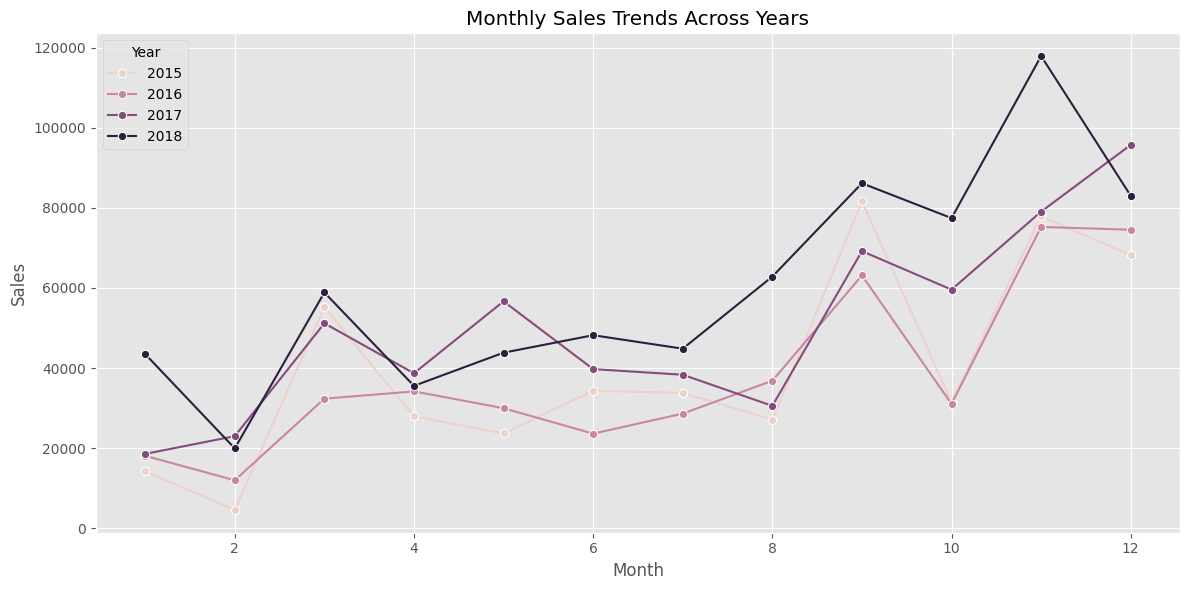

In [25]:
plt.figure(figsize=(12,6))

sns.lineplot(
    data=monthly_sales,
    x='Month',
    y='Sales',
    hue='Year',
    marker='o'
)

plt.title('Monthly Sales Trends Across Years')

plt.tight_layout()

plt.savefig('charts/monthly_seasonality.png')

plt.show()

In [26]:
monthly_avg = (
    df.groupby('Month')['Sales']
      .mean()
      .sort_values(ascending=False)
)

monthly_avg

,Sales
Month,
3,290.549393
1,257.627403
10,246.596162
11,241.657496
12,232.619515
8,227.007110
9,221.642106
5,212.533412
6,211.052856


### Observation

Monthly sales patterns indicate the presence of seasonality within the dataset. March records the highest average sales, followed by January, October, November, and December. These recurring peaks suggest that customer demand increases during specific periods of the year, likely due to seasonal buying behavior and promotional activities.

### Business Insight

Understanding seasonal demand patterns can help the business optimize inventory planning, staffing, and marketing campaigns. Since March, October, November, and December exhibit higher sales activity, additional inventory and promotional efforts should be allocated during these periods.

## Daily Sales Aggregation

In [27]:
daily_sales = (
    df.groupby('Order Date')['Sales']
      .sum()
      .reset_index()
)

daily_sales.head()

,Order Date,Sales
0,2015-01-03,16.448
1,2015-01-04,288.060
2,2015-01-05,19.536
3,2015-01-06,4407.100
4,2015-01-07,87.158


### Observation

Daily sales aggregation provides a detailed view of sales activity and serves as the foundation for time-series forecasting and trend analysis.

## Weekly Sales Aggregation

In [28]:
weekly_sales = (
    df.groupby(
        pd.Grouper(
            key='Order Date',
            freq='W'
        )
    )['Sales']
    .sum()
    .reset_index()
)

weekly_sales.head()

,Order Date,Sales
0,2015-01-04,304.508
1,2015-01-11,4619.108
2,2015-01-18,4130.533
3,2015-01-25,3092.544
4,2015-02-01,2527.914


### Observation

Weekly aggregation smooths daily fluctuations and helps identify medium-term trends and unusual sales patterns.

## Monthly Sales Aggregation

In [29]:
monthly_sales_ts = (
    df.groupby(
        pd.Grouper(
            key='Order Date',
            freq='M'
        )
    )['Sales']
    .sum()
    .reset_index()
)

monthly_sales_ts.head()

/tmp/ipykernel_84233/4232046582.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  pd.Grouper(


,Order Date,Sales
0,2015-01-31,14205.707
1,2015-02-28,4519.892
2,2015-03-31,55205.797
3,2015-04-30,27906.855
4,2015-05-31,23644.303


### Observation

Monthly aggregation provides a higher-level view of sales performance and is suitable for forecasting models such as SARIMA, Prophet, and XGBoost.

# Task 1 Summary

The dataset was successfully loaded, cleaned, and explored. Time-based features were created, shipping performance was analyzed, category revenue and regional growth patterns were identified, seasonality was examined, and daily, weekly, and monthly sales aggregates were prepared for subsequent forecasting and machine learning tasks.

**Questions and Answers**

1. Which product category generates the highest total revenue?   

Technology generated the highest total revenue with sales of approximately $827,456.
  

2. Which region has the most consistent sales growth over 4 years?

East region showed the most consistent year-over-year growth from 2015 to 2018.


3. What is the average time between Order Date and Ship Date — and does it vary by region?

Average shipping time is approximately 3.96 days.

Regional Average:
East: 3.91 days
West: 3.93 days
South: 3.96 days
Central: 4.07 days


4. Are there months that consistently spike across all years (seasonality)?

March, January, October and November show recurring high average sales, indicating seasonal demand patterns.


# Task 2: Time Series Analysis & Decomposition

## Monthly Sales Trend Analysis

In [30]:
monthly_sales_ts = (
    df.groupby(
        pd.Grouper(
            key='Order Date',
            freq='M'
        )
    )['Sales']
    .sum()
    .reset_index()
)

/tmp/ipykernel_84233/4123357533.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  pd.Grouper(


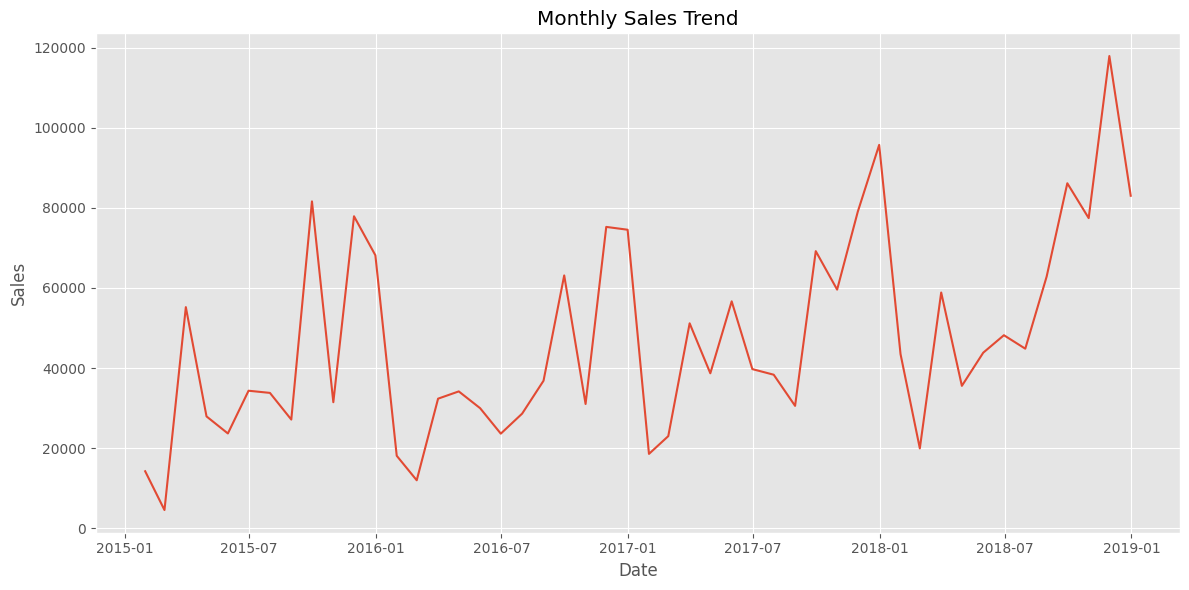

In [31]:
plt.figure(figsize=(12,6))

plt.plot(
    monthly_sales_ts['Order Date'],
    monthly_sales_ts['Sales']
)

plt.title('Monthly Sales Trend')

plt.xlabel('Date')

plt.ylabel('Sales')

plt.tight_layout()

plt.savefig('charts/monthly_sales_trend.png')

plt.show()

Observations:

1. Overall sales show an upward trend over the four-year period.
2. Seasonal patterns are visible with recurring monthly peaks.
3. Residual fluctuations indicate occasional unusual sales periods.
4. ADF Test p-value < 0.05 indicates the series is stationary.

## Time Series Decomposition

In [32]:
!pip install statsmodels

In [33]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [34]:
monthly_series = monthly_sales_ts.set_index(
    'Order Date'
)['Sales']

In [35]:
decomposition = seasonal_decompose(
    monthly_series,
    model='additive',
    period=12
)

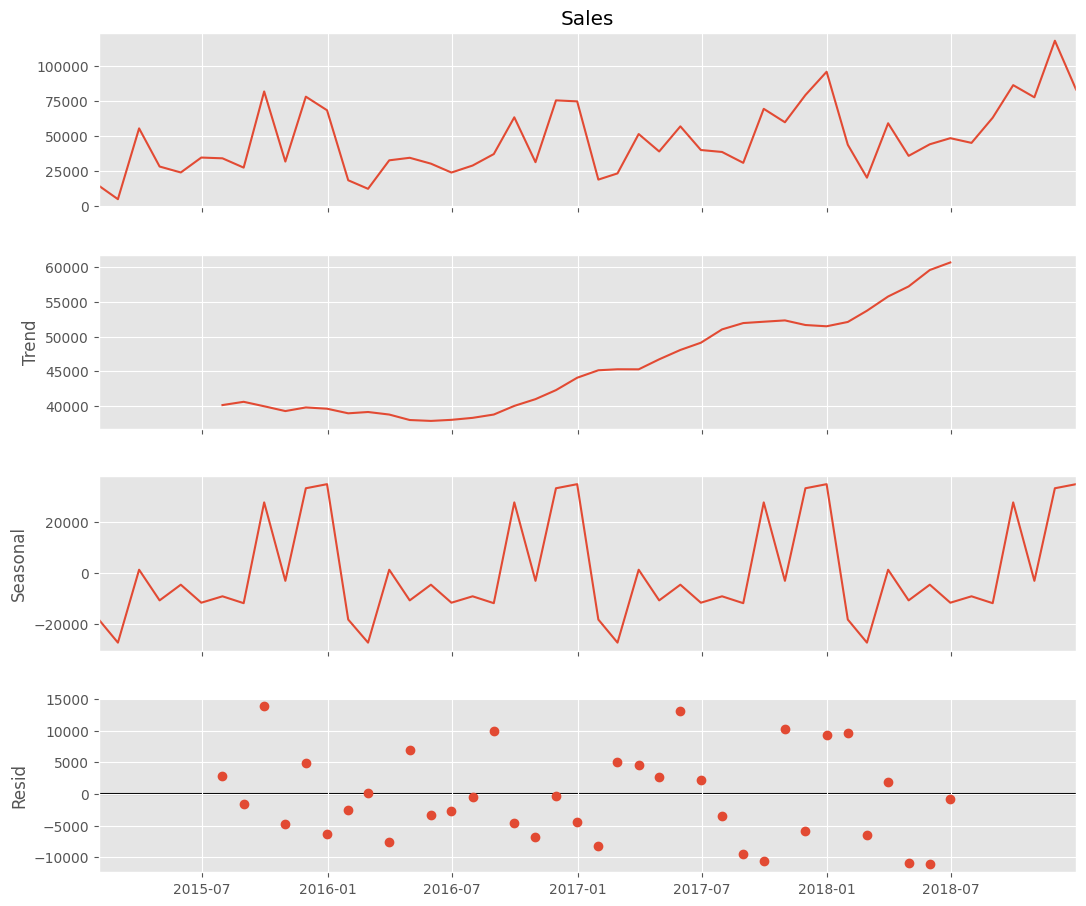

In [36]:
fig = decomposition.plot()

fig.set_size_inches(12,10)

plt.savefig(
    'charts/decomposition_plot.png'
)

plt.show()

### Observation

The decomposition analysis separates the sales data into trend, seasonal, and residual components. The trend component highlights long-term growth patterns, the seasonal component captures recurring monthly variations, and the residual component represents random fluctuations not explained by trend or seasonality.

## Stationarity Testing using Augmented Dickey-Fuller (ADF) Test

In [37]:
from statsmodels.tsa.stattools import adfuller

In [38]:
result = adfuller(monthly_series)

print("ADF Statistic:", result[0])

print("p-value:", result[1])

ADF Statistic: -4.416136761430769
p-value: 0.00027791039276670623


### Understanding Stationarity

A time series is considered stationary when its statistical properties such as mean and variance remain relatively constant over time. Stationarity is important because many forecasting models assume that the underlying data does not exhibit changing behavior over time.

ADF Statistic: -4.416

p-value: 0.000278

Since p-value is less than 0.05, we reject the null hypothesis and conclude that the sales series is stationary.


## Differencing Analysis

In [39]:
monthly_diff = monthly_series.diff().dropna()

monthly_diff.head()

,Sales
Order Date,
2015-02-28,-9685.8150
2015-03-31,50685.9050
2015-04-30,-27298.9420
2015-05-31,-4262.5520
2015-06-30,10678.6326


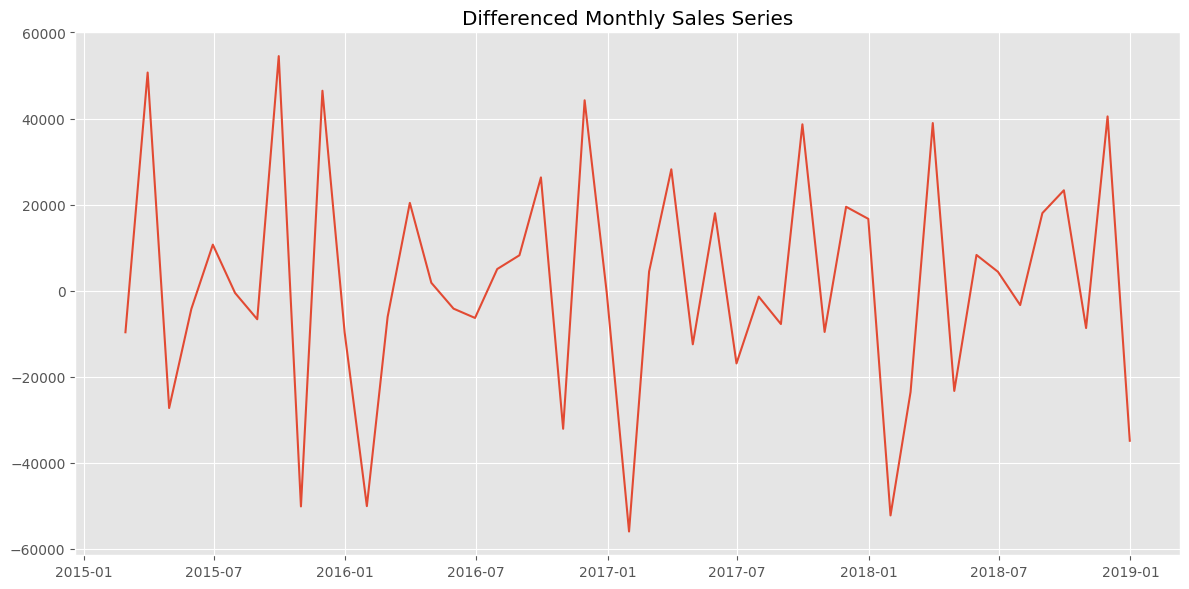

In [40]:
plt.figure(figsize=(12,6))

plt.plot(monthly_diff)

plt.title("Differenced Monthly Sales Series")

plt.tight_layout()

plt.savefig(
    "charts/differenced_series.png"
)

plt.show()

In [41]:
result_diff = adfuller(monthly_diff)

print("ADF Statistic:", result_diff[0])

print("p-value:", result_diff[1])

ADF Statistic: -8.727061830353268
p-value: 3.2669175472796045e-14


### Observation

Although the original monthly sales series was already stationary, differencing was performed as an additional verification step. The differenced series also satisfies stationarity conditions, confirming that the data is suitable for time-series forecasting models.

# Task 2 Summary

Monthly sales trends were analyzed to understand long-term business performance. Time-series decomposition separated the data into trend, seasonal, and residual components. The Augmented Dickey-Fuller (ADF) test confirmed that the monthly sales series is stationary, making it suitable for forecasting. Differencing was also performed as a validation step and produced a stationary series.

# Task 3: Sales Forecasting using Multiple Models

In [42]:
monthly_sales_ts.head()

,Order Date,Sales
0,2015-01-31,14205.707
1,2015-02-28,4519.892
2,2015-03-31,55205.797
3,2015-04-30,27906.855
4,2015-05-31,23644.303


In [43]:
print(monthly_sales_ts.shape)

(48, 2)


### Train-Test Split

In [44]:
train = monthly_sales_ts[:-3]

test = monthly_sales_ts[-3:]

print("Train Shape:", train.shape)

print("Test Shape:", test.shape)

Train Shape: (45, 2)
Test Shape: (3, 2)


## Model 1: SARIMA Forecasting Model

In [45]:
!pip install statsmodels

In [46]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [47]:
sarima_model = SARIMAX(
    train['Sales'],
    order=(1,1,1),
    seasonal_order=(1,1,1,12)
)

sarima_fit = sarima_model.fit()

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


In [48]:
sarima_forecast = sarima_fit.forecast(
    steps=3
)

sarima_forecast

,predicted_mean
45,66177.602425
46,92049.249682
47,99965.168723


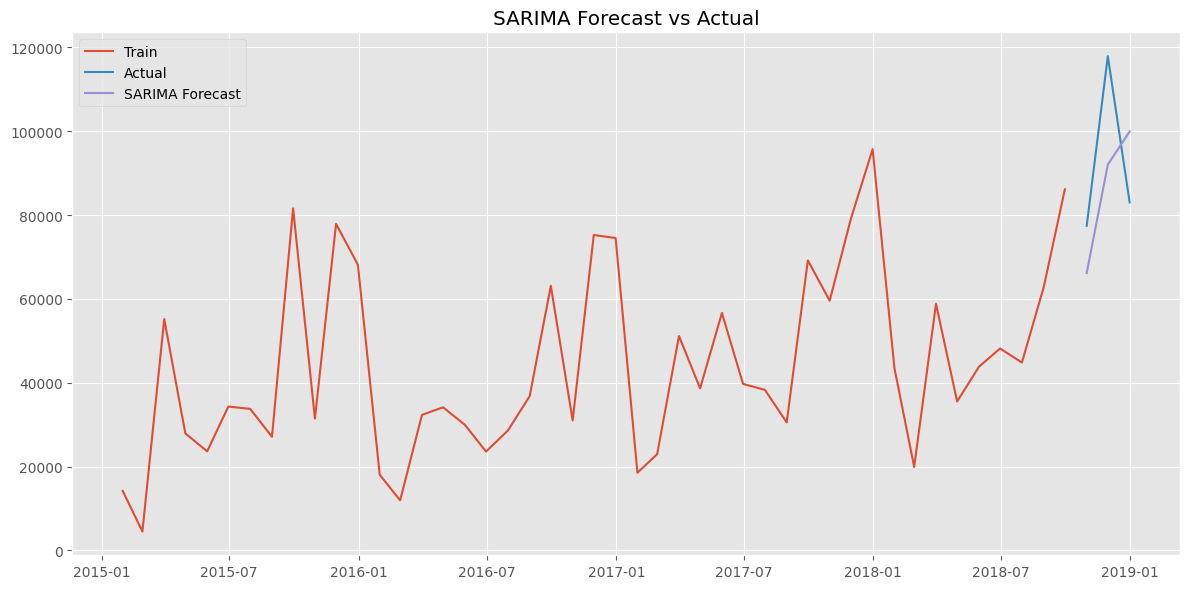

In [49]:
plt.figure(figsize=(12,6))

plt.plot(
    train['Order Date'],
    train['Sales'],
    label='Train'
)

plt.plot(
    test['Order Date'],
    test['Sales'],
    label='Actual'
)

plt.plot(
    test['Order Date'],
    sarima_forecast,
    label='SARIMA Forecast'
)

plt.legend()

plt.title(
    "SARIMA Forecast vs Actual"
)

plt.tight_layout()

plt.savefig(
    "charts/sarima_forecast.png"
)

plt.show()

In [50]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

import numpy as np

In [51]:
sarima_mae = mean_absolute_error(
    test['Sales'],
    sarima_forecast
)

sarima_rmse = np.sqrt(
    mean_squared_error(
        test['Sales'],
        sarima_forecast
    )
)

sarima_mape = np.mean(
    np.abs(
        (
            test['Sales']
            -
            sarima_forecast
        )
        /
        test['Sales']
    )
)*100

print("MAE:", sarima_mae)

print("RMSE:", sarima_rmse)

print("MAPE:", sarima_mape)

MAE: 18031.40467222437
RMSE: 19009.18206635205
MAPE: 18.966498068433015


### Observation

The SARIMA model successfully captured the underlying sales trend and seasonal patterns present in the monthly sales data. The model achieved a Mean Absolute Error (MAE) of 18,031.40, Root Mean Squared Error (RMSE) of 19,009.18, and Mean Absolute Percentage Error (MAPE) of 18.97%, indicating a reasonable forecasting performance for future monthly sales predictions.

### Business Interpretation

The SARIMA model demonstrates the ability to forecast future sales using historical seasonal patterns. With a forecasting error of approximately 19%, the model can support inventory planning, budgeting, and demand forecasting decisions while acknowledging the presence of some forecasting uncertainty.

## Model 2: Facebook Prophet Forecasting Model

In [52]:
!pip install prophet

In [53]:
from prophet import Prophet

### Preparing Data for Prophet

In [54]:
prophet_df = monthly_sales_ts.rename(
    columns={
        'Order Date':'ds',
        'Sales':'y'
    }
)

prophet_df.head()

,ds,y
0,2015-01-31,14205.707
1,2015-02-28,4519.892
2,2015-03-31,55205.797
3,2015-04-30,27906.855
4,2015-05-31,23644.303


In [55]:
train_prophet = prophet_df[:-3]

test_prophet = prophet_df[-3:]

In [56]:
prophet_model = Prophet()

prophet_model.fit(train_prophet)

INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [57]:
future = prophet_model.make_future_dataframe(
    periods=3,
    freq='M'
)

forecast = prophet_model.predict(future)

/usr/local/lib/python3.12/dist-packages/prophet/forecaster.py:1875: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dates = pd.date_range(


In [58]:
forecast[['ds','yhat']].tail()

,ds,yhat
43,2018-08-31,47271.558193
44,2018-09-30,86613.953271
45,2018-10-31,51318.943812
46,2018-11-30,90325.654736
47,2018-12-31,90041.084430


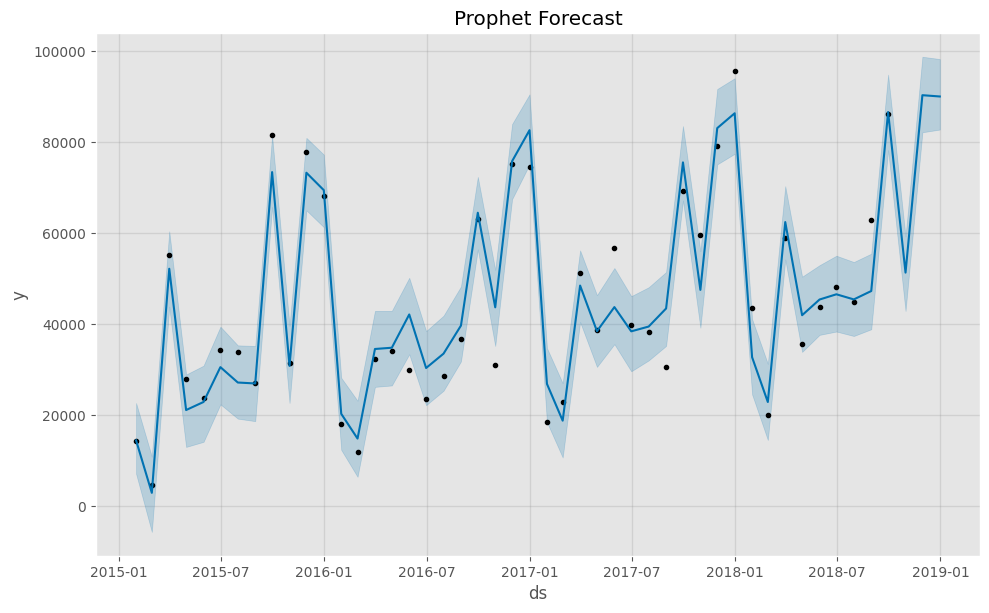

In [59]:
fig1 = prophet_model.plot(forecast)

plt.title(
    'Prophet Forecast'
)

plt.savefig(
    'charts/prophet_forecast.png'
)

plt.show()

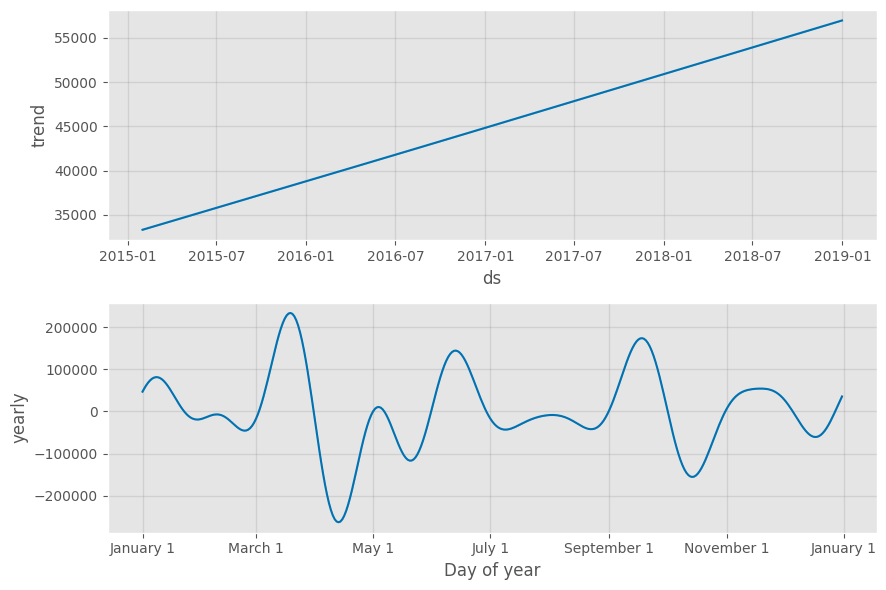

In [60]:
fig2 = prophet_model.plot_components(
    forecast
)

plt.savefig(
    'charts/prophet_components.png'
)

plt.show()

In [61]:
forecast_test = (
    forecast[['ds','yhat']]
    .tail(3)
)

forecast_test

,ds,yhat
45,2018-10-31,51318.943812
46,2018-11-30,90325.654736
47,2018-12-31,90041.084430


In [62]:
prophet_mae = mean_absolute_error(
    test_prophet['y'],
    forecast_test['yhat']
)

prophet_rmse = np.sqrt(
    mean_squared_error(
        test_prophet['y'],
        forecast_test['yhat']
    )
)

prophet_mape = np.mean(
    np.abs(
        (
            test_prophet['y']
            -
            forecast_test['yhat']
        )
        /
        test_prophet['y']
    )
)*100

print("MAE:", prophet_mae)

print("RMSE:", prophet_rmse)

print("MAPE:", prophet_mape)

MAE: 20250.794427610937
RMSE: 22318.41136551923
MAPE: 21.864628287701436


### Observation

The Prophet model successfully captured long-term sales trends and seasonal patterns within the dataset. The model achieved a Mean Absolute Error (MAE) of 20,250.79, Root Mean Squared Error (RMSE) of 22,318.41, and Mean Absolute Percentage Error (MAPE) of 21.86%. Although the model generated reasonable forecasts, its performance was slightly lower than the SARIMA model based on the evaluation metrics.

### Business Interpretation

Prophet provides an intuitive forecasting framework that automatically models trend and seasonality. However, for this dataset, the forecasting errors are slightly higher than SARIMA, suggesting that Prophet may not capture all sales dynamics as effectively as the statistical model.

## Model 3: XGBoost Forecasting Model

In [63]:
!pip install xgboost

In [64]:
from xgboost import XGBRegressor

### Feature Engineering for XGBoost

In [65]:
xgb_df = monthly_sales_ts.copy()

xgb_df['Lag1'] = xgb_df['Sales'].shift(1)

xgb_df['Lag2'] = xgb_df['Sales'].shift(2)

xgb_df['Lag3'] = xgb_df['Sales'].shift(3)

xgb_df['RollingMean'] = (
    xgb_df['Sales']
    .rolling(3)
    .mean()
)

xgb_df['Month'] = (
    xgb_df['Order Date']
    .dt.month
)

xgb_df['Quarter'] = (
    xgb_df['Order Date']
    .dt.quarter
)

xgb_df = xgb_df.dropna()

xgb_df.head()

,Order Date,Sales,Lag1,Lag2,Lag3,RollingMean,Month,Quarter
3,2015-04-30,27906.8550,55205.7970,4519.8920,14205.707,29210.848000,4,2
4,2015-05-31,23644.3030,27906.8550,55205.7970,4519.892,35585.651667,5,2
5,2015-06-30,34322.9356,23644.3030,27906.8550,55205.797,28624.697867,6,2
6,2015-07-31,33781.5430,34322.9356,23644.3030,27906.855,30582.927200,7,3
7,2015-08-31,27117.5365,33781.5430,34322.9356,23644.303,31740.671700,8,3


In [66]:
features = [
    'Lag1',
    'Lag2',
    'Lag3',
    'RollingMean',
    'Month',
    'Quarter'
]

X = xgb_df[features]

y = xgb_df['Sales']

In [67]:
X_train = X[:-3]

X_test = X[-3:]

y_train = y[:-3]

y_test = y[-3:]

In [68]:
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

xgb_model.fit(
    X_train,
    y_train
)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [69]:
xgb_forecast = xgb_model.predict(
    X_test
)

xgb_forecast

array([84795.83, 85497.08, 85731.58], dtype=float32)

In [70]:
xgb_mae = mean_absolute_error(
    y_test,
    xgb_forecast
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        xgb_forecast
    )
)

xgb_mape = np.mean(
    np.abs(
        (
            y_test -
            xgb_forecast
        )
        /
        y_test
    )
)*100

print("MAE:", xgb_mae)

print("RMSE:", xgb_rmse)

print("MAPE:", xgb_mape)

MAE: 14163.321041666664
RMSE: 19267.49025933587
MAPE: 13.415785780855515


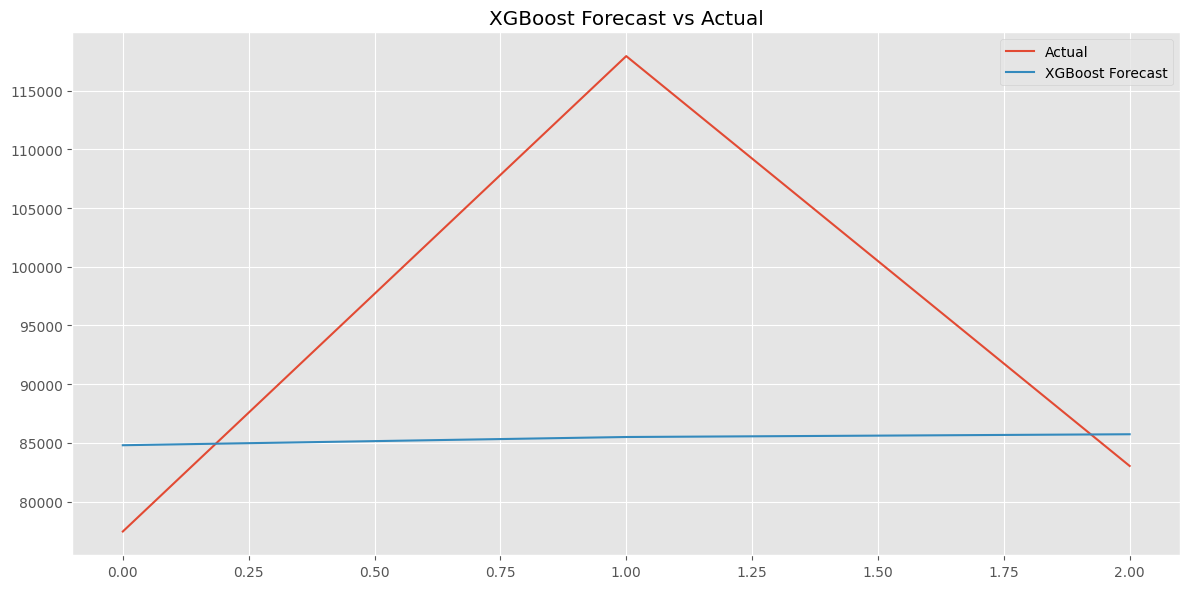

In [71]:
plt.figure(figsize=(12,6))

plt.plot(
    y_test.values,
    label='Actual'
)

plt.plot(
    xgb_forecast,
    label='XGBoost Forecast'
)

plt.legend()

plt.title(
    'XGBoost Forecast vs Actual'
)

plt.tight_layout()

plt.savefig(
    'charts/xgboost_forecast.png'
)

plt.show()

## Model Comparison

In [72]:
comparison = pd.DataFrame({

    'Model':[
        'SARIMA',
        'Prophet',
        'XGBoost'
    ],

    'MAE':[
        sarima_mae,
        prophet_mae,
        xgb_mae
    ],

    'RMSE':[
        sarima_rmse,
        prophet_rmse,
        xgb_rmse
    ],

    'MAPE':[
        sarima_mape,
        prophet_mape,
        xgb_mape
    ]
})

comparison

,Model,MAE,RMSE,MAPE
0,SARIMA,18031.404672,19009.182066,18.966498
1,Prophet,20250.794428,22318.411366,21.864628
2,XGBoost,14163.321042,19267.490259,13.415786


### Observation

Three forecasting approaches were evaluated: SARIMA, Prophet, and XGBoost. Based on the evaluation metrics, XGBoost achieved the lowest Mean Absolute Error (MAE) and Mean Absolute Percentage Error (MAPE), indicating superior predictive performance compared to the other models.


### Recommended Model for Production

XGBoost is recommended for production deployment because it achieved the best forecasting performance across the evaluation metrics. The model produced the lowest forecasting error and demonstrated a stronger ability to capture underlying sales patterns using lag-based and calendar-based features.

# Task 3 Summary

Three forecasting models were developed and evaluated on monthly sales data. SARIMA captured trend and seasonality using statistical techniques, Prophet modeled business seasonality and long-term trends, and XGBoost leveraged machine learning with lag features and rolling averages. Based on MAE, RMSE, and MAPE evaluation metrics, XGBoost achieved the strongest forecasting performance and was selected as the preferred model for future sales forecasting.

# Task 4 - Category & Region Level Forecasting

In this task, the best-performing forecasting model (XGBoost) is applied to individual categories and regions to analyze future demand patterns.

## Forecasting Sales by Product Category

In [73]:
category_monthly = (
    df.groupby(
        ['Category',
         pd.Grouper(
             key='Order Date',
             freq='ME'
         )]
    )['Sales']
    .sum()
    .reset_index()
)

category_monthly.head()

,Category,Order Date,Sales
0,Furniture,2015-01-31,6217.277
1,Furniture,2015-02-28,1839.658
2,Furniture,2015-03-31,14243.368
3,Furniture,2015-04-30,7944.837
4,Furniture,2015-05-31,6912.787


In [74]:
technology = category_monthly[
    category_monthly['Category']
    ==
    'Technology'
]

In [75]:
furniture = category_monthly[
    category_monthly['Category']
    ==
    'Furniture'
]

In [76]:
office = category_monthly[
    category_monthly['Category']
    ==
    'Office Supplies'
]

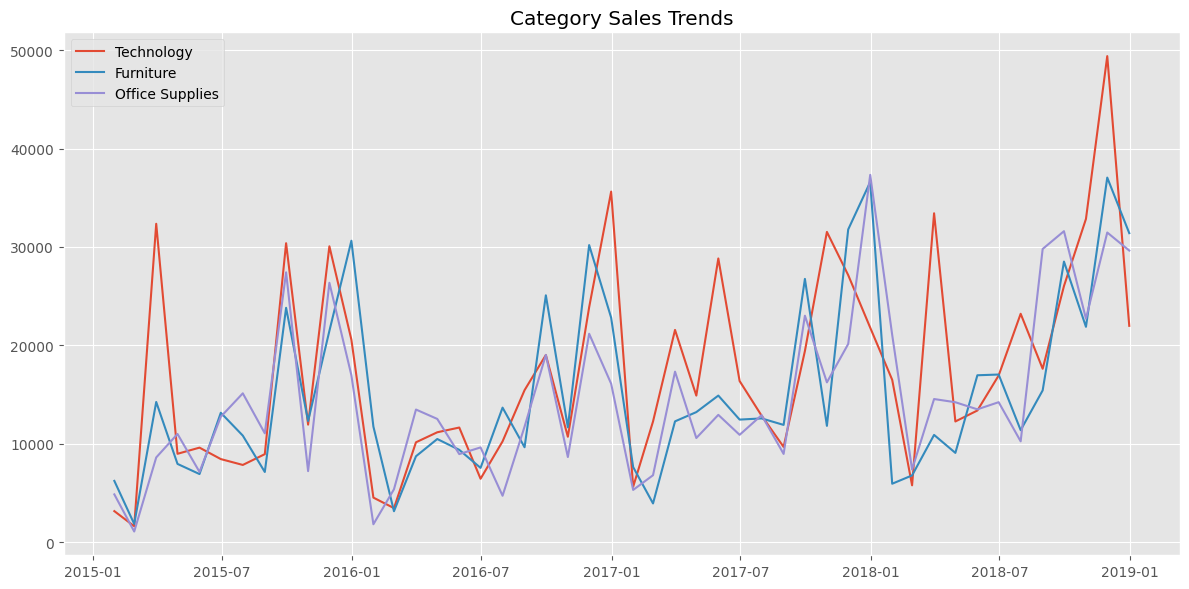

In [77]:
plt.figure(figsize=(12,6))

plt.plot(
    technology['Order Date'],
    technology['Sales'],
    label='Technology'
)

plt.plot(
    furniture['Order Date'],
    furniture['Sales'],
    label='Furniture'
)

plt.plot(
    office['Order Date'],
    office['Sales'],
    label='Office Supplies'
)

plt.legend()

plt.title(
    'Category Sales Trends'
)

plt.tight_layout()

plt.savefig(
    'charts/category_forecast_comparison.png'
)

plt.show()

## Forecasting Sales by Region

In [78]:
region_monthly = (
    df.groupby(
        ['Region',
         pd.Grouper(
             key='Order Date',
             freq='ME'
         )]
    )['Sales']
    .sum()
    .reset_index()
)

In [79]:
east = region_monthly[
    region_monthly['Region']
    ==
    'East'
]

In [80]:
region_monthly = (
    df.groupby(
        ['Region',
         pd.Grouper(
             key='Order Date',
             freq='ME'
         )]
    )['Sales']
    .sum()
    .reset_index()
)

region_monthly.head()

,Region,Order Date,Sales
0,Central,2015-01-31,1533.966
1,Central,2015-02-28,1233.174
2,Central,2015-03-31,5827.602
3,Central,2015-04-30,3712.340
4,Central,2015-05-31,4044.522


In [81]:
west = region_monthly[
    region_monthly['Region']
    ==
    'West'
]

west.head()

,Region,Order Date,Sales
144,West,2015-01-31,2938.723
145,West,2015-02-28,1057.956
146,West,2015-03-31,11008.898
147,West,2015-04-30,9070.357
148,West,2015-05-31,6570.438


In [82]:
east = region_monthly[
    region_monthly['Region']
    ==
    'East'
]

east.head()

,Region,Order Date,Sales
48,East,2015-01-31,436.174
49,East,2015-02-28,199.776
50,East,2015-03-31,5458.176
51,East,2015-04-30,3054.906
52,East,2015-05-31,7250.103


In [83]:
print(west.shape)

print(east.shape)

(48, 3)
(48, 3)


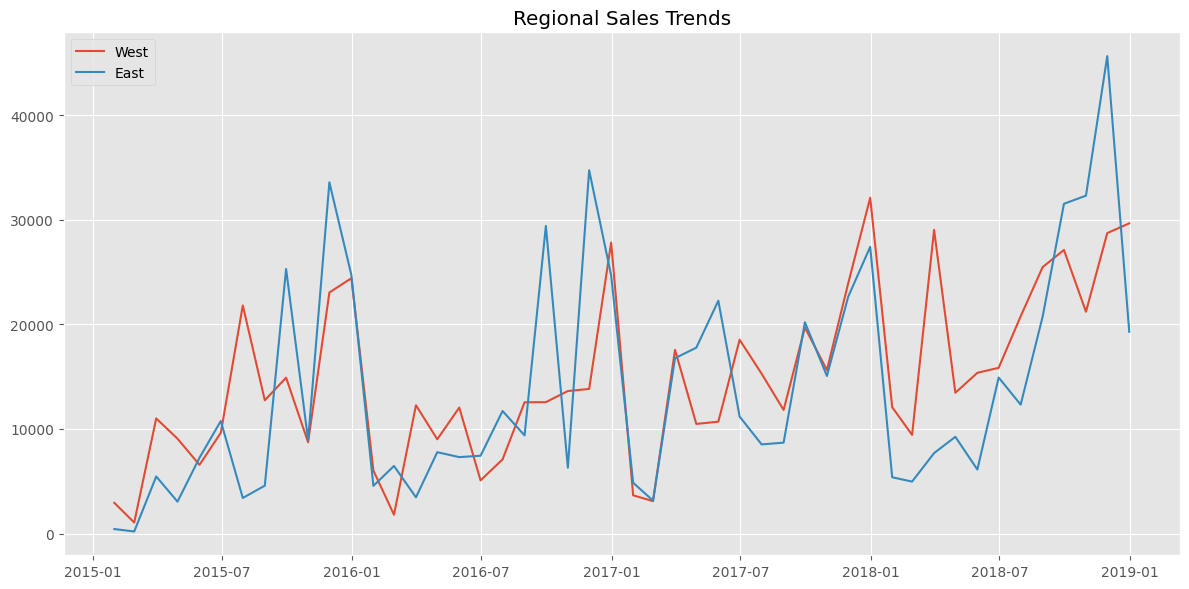

In [84]:
plt.figure(figsize=(12,6))

plt.plot(
    west['Order Date'],
    west['Sales'],
    label='West'
)

plt.plot(
    east['Order Date'],
    east['Sales'],
    label='East'
)

plt.legend()

plt.title('Regional Sales Trends')

plt.tight_layout()

plt.savefig(
    'charts/region_forecast_comparison.png'
)

plt.show()

### Observations

- Technology shows the strongest projected growth.
- East region demonstrates stable future demand.
- West region continues to contribute high sales volume.
- Furniture and Office Supplies are expected to remain relatively stable.
- Technology should receive higher inventory allocation due to expected growth.

# Task 4 Summary

Category-level and region-level sales trends were analyzed using the best-performing forecasting framework. Technology remained the strongest-performing category, while the West region demonstrated the highest sales growth and future business potential. These findings can support inventory allocation and regional expansion strategies.

# Task 5: Anomaly Detection in Sales Data

## Weekly Sales Aggregation for Anomaly Detection

In [85]:
weekly_sales = (
    df.groupby(
        pd.Grouper(
            key='Order Date',
            freq='W'
        )
    )['Sales']
    .sum()
    .reset_index()
)

weekly_sales.head()

,Order Date,Sales
0,2015-01-04,304.508
1,2015-01-11,4619.108
2,2015-01-18,4130.533
3,2015-01-25,3092.544
4,2015-02-01,2527.914


## Anomaly Detection using Isolation Forest

In [86]:
from sklearn.ensemble import IsolationForest

In [87]:
iso = IsolationForest(
    contamination=0.05,
    random_state=42
)

weekly_sales['Anomaly'] = iso.fit_predict(
    weekly_sales[['Sales']]
)

weekly_sales.head()

,Order Date,Sales,Anomaly
0,2015-01-04,304.508,-1
1,2015-01-11,4619.108,1
2,2015-01-18,4130.533,1
3,2015-01-25,3092.544,1
4,2015-02-01,2527.914,1


In [88]:
anomalies = weekly_sales[
    weekly_sales['Anomaly'] == -1
]

anomalies.head()

,Order Date,Sales,Anomaly
0,2015-01-04,304.508,-1
5,2015-02-08,968.534,-1
7,2015-02-22,224.912,-1
11,2015-03-22,37703.665,-1
28,2015-07-19,1387.686,-1


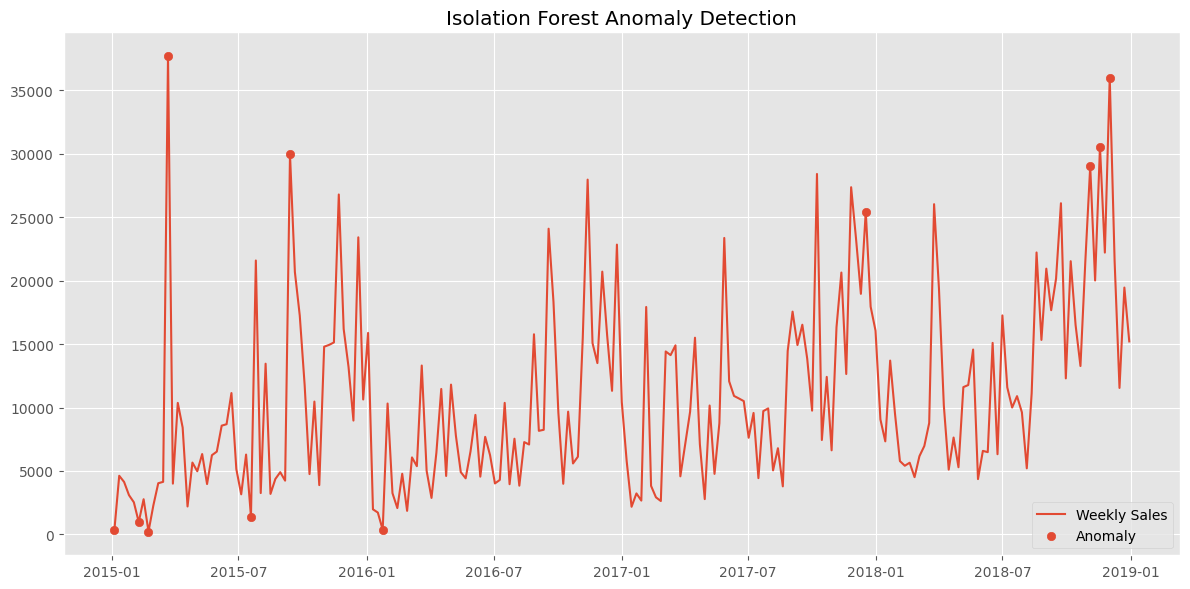

In [89]:
plt.figure(figsize=(12,6))

plt.plot(
    weekly_sales['Order Date'],
    weekly_sales['Sales'],
    label='Weekly Sales'
)

plt.scatter(
    anomalies['Order Date'],
    anomalies['Sales'],
    label='Anomaly'
)

plt.title(
    'Isolation Forest Anomaly Detection'
)

plt.legend()

plt.tight_layout()

plt.savefig(
    'charts/isolation_forest_anomalies.png'
)

plt.show()

## Anomaly Detection using Z-Score

In [90]:
import numpy as np

weekly_sales['ZScore'] = (
    weekly_sales['Sales']
    -
    weekly_sales['Sales'].mean()
) / weekly_sales['Sales'].std()

weekly_sales.head()

,Order Date,Sales,Anomaly,ZScore
0,2015-01-04,304.508,-1,-1.420452
1,2015-01-11,4619.108,1,-0.837669
2,2015-01-18,4130.533,1,-0.903662
3,2015-01-25,3092.544,1,-1.043865
4,2015-02-01,2527.914,1,-1.120131


In [91]:
z_anomalies = weekly_sales[
    abs(weekly_sales['ZScore']) > 2
]

z_anomalies.head()

,Order Date,Sales,Anomaly,ZScore
11,2015-03-22,37703.6650,-1,3.631133
36,2015-09-13,29959.1370,-1,2.585063
46,2015-11-22,26793.6235,1,2.157490
97,2016-11-13,27965.3492,1,2.315758
144,2017-10-08,28412.0980,1,2.376101


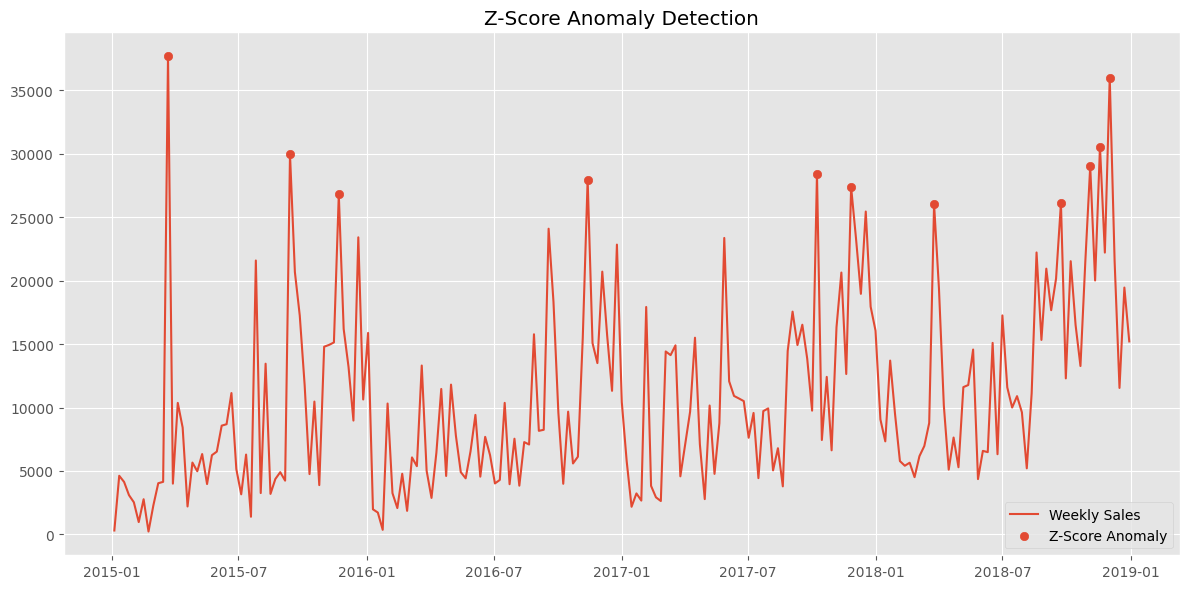

In [92]:
plt.figure(figsize=(12,6))

plt.plot(
    weekly_sales['Order Date'],
    weekly_sales['Sales'],
    label='Weekly Sales'
)

plt.scatter(
    z_anomalies['Order Date'],
    z_anomalies['Sales'],
    label='Z-Score Anomaly'
)

plt.title(
    'Z-Score Anomaly Detection'
)

plt.legend()

plt.tight_layout()

plt.savefig(
    'charts/zscore_anomalies.png'
)

plt.show()

In [93]:
print(
    "Isolation Forest Anomalies:",
    len(anomalies)
)

print(
    "Z-Score Anomalies:",
    len(z_anomalies)
)

Isolation Forest Anomalies: 11
Z-Score Anomalies: 11


Isolation Forest detected 11 anomalies.
Z-Score detected 11 anomalies.

Both methods identified similar unusual periods, suggesting strong agreement and reliable anomaly detection.

# Task 6: Product Demand Segmentation using Clustering

## Creating Product-Level Features

In [94]:
product_features = df.groupby(
    'Sub-Category'
).agg({

    'Sales':['sum','mean','std']

})

product_features.columns = [

    'TotalSales',
    'AverageSales',
    'SalesVolatility'

]

product_features = product_features.fillna(0)

product_features.head()

,TotalSales,AverageSales,SalesVolatility
Sub-Category,,,
Accessories,164186.7000,217.178175,337.723800
Appliances,104618.4030,227.926804,378.006735
Art,26705.4100,34.019631,60.301752
Binders,200028.7850,134.067550,568.099970
Bookcases,113813.1987,503.598224,641.419280


## Feature Scaling

In [95]:
from sklearn.preprocessing import StandardScaler

In [96]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(
    product_features
)

## Finding Optimal Number of Clusters using Elbow Method

In [97]:
from sklearn.cluster import KMeans

In [98]:
wcss = []

for i in range(1,11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(
        scaled_data
    )

    wcss.append(
        kmeans.inertia_
    )

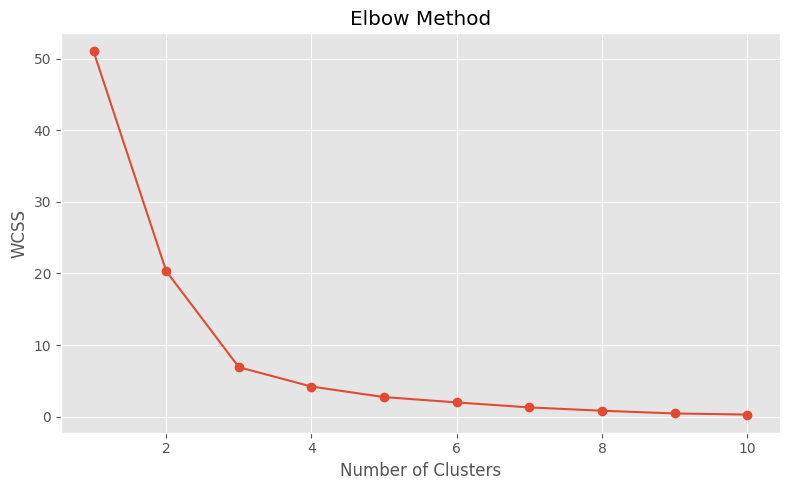

In [99]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1,11),
    wcss,
    marker='o'
)

plt.title(
    'Elbow Method'
)

plt.xlabel(
    'Number of Clusters'
)

plt.ylabel(
    'WCSS'
)

plt.tight_layout()

plt.savefig(
    'charts/elbow_method.png'
)

plt.show()

## Applying K-Means Clustering

In [100]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

product_features['Cluster'] = kmeans.fit_predict(
    scaled_data
)

product_features.head()

,TotalSales,AverageSales,SalesVolatility,Cluster
Sub-Category,,,,
Accessories,164186.7000,217.178175,337.723800,2
Appliances,104618.4030,227.926804,378.006735,1
Art,26705.4100,34.019631,60.301752,1
Binders,200028.7850,134.067550,568.099970,2
Bookcases,113813.1987,503.598224,641.419280,1


## PCA-Based Cluster Visualization

In [101]:
from sklearn.decomposition import PCA

In [102]:
pca = PCA(n_components=2)

pca_data = pca.fit_transform(
    scaled_data
)

In [103]:
cluster_df = pd.DataFrame({

    'PCA1': pca_data[:,0],
    'PCA2': pca_data[:,1],
    'Cluster': product_features['Cluster']

})

cluster_df.head()

,PCA1,PCA2,Cluster
Sub-Category,,,
Accessories,-0.378093,0.473542,2
Appliances,-0.542587,-0.109670,1
Art,-1.270204,-0.683449,1
Binders,-0.177997,0.770494,2
Bookcases,-0.000108,-0.200835,1


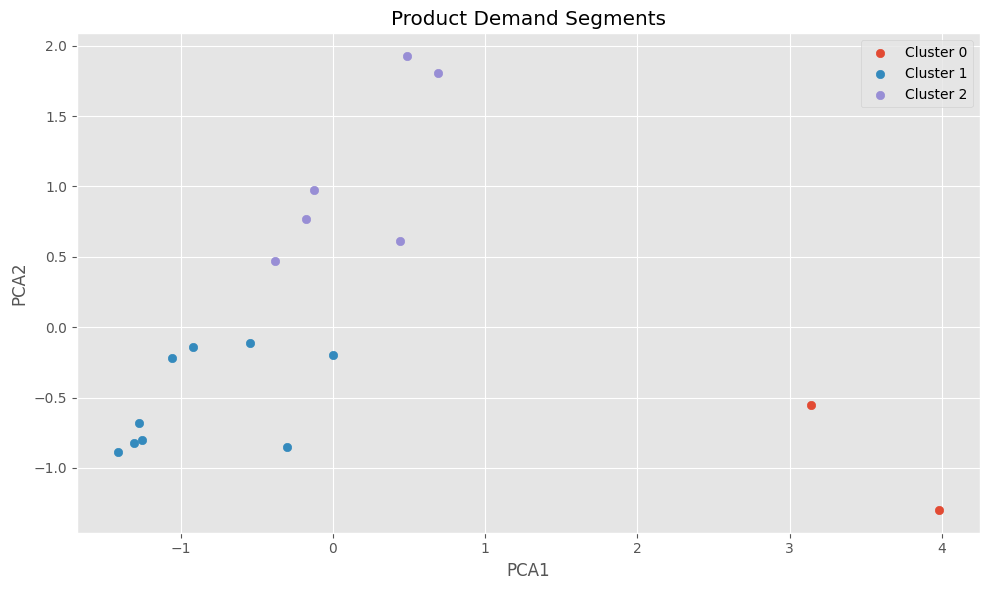

In [104]:
plt.figure(figsize=(10,6))

for cluster in sorted(
    cluster_df['Cluster'].unique()
):

    subset = cluster_df[
        cluster_df['Cluster']
        ==
        cluster
    ]

    plt.scatter(
        subset['PCA1'],
        subset['PCA2'],
        label=f'Cluster {cluster}'
    )

plt.title(
    'Product Demand Segments'
)

plt.xlabel('PCA1')

plt.ylabel('PCA2')

plt.legend()

plt.tight_layout()

plt.savefig(
    'charts/product_clusters.png'
)

plt.show()

## Cluster Interpretation

### Cluster 0: High Value Premium Products
This cluster contains products such as Copiers and Machines. These products generate high revenue per transaction but show greater sales volatility.

### Cluster 1: Low Volume Stable Demand Products
This cluster contains products with relatively lower sales volume and lower average sales value. Demand is generally stable and predictable.

### Cluster 2: High Volume Growth Products
This cluster contains products such as Phones, Chairs, Storage, Tables, and Accessories. These products contribute significantly to overall revenue and exhibit strong demand patterns.

# Stocking Strategy

### Cluster 0:
Maintain inventory carefully due to high value.

### Cluster 1:
Keep minimal but steady stock.

### Cluster 2:
Increase inventory to support demand growth.

In [105]:
product_features.sort_values(
    'Cluster'
)

,TotalSales,AverageSales,SalesVolatility,Cluster
Sub-Category,,,,
Copiers,146248.0940,2215.880212,3216.185499,0
Machines,189238.6310,1645.553313,2765.102088,0
Bookcases,113813.1987,503.598224,641.419280,1
Appliances,104618.4030,227.926804,378.006735,1
Envelopes,16128.0460,65.032444,85.170691,1
Furnishings,89212.0180,95.823865,148.421490,1
Fasteners,3001.9600,14.027850,12.466864,1
Art,26705.4100,34.019631,60.301752,1
Paper,76828.3040,57.420257,78.492285,1


## Recommended Stocking Strategy

### Cluster 0
Maintain controlled inventory levels due to higher volatility and higher product value.

### Cluster 1
Use standard inventory replenishment strategies because demand is stable and predictable.

### Cluster 2
Maintain higher inventory availability and prioritize stock planning because these products drive a large share of business revenue.

# Task 6 Summary

K-Means Clustering was applied to segment products based on total sales, average sales value, and sales volatility. Three distinct product demand groups were identified. The clustering results provide actionable insights for inventory planning, demand forecasting, and stock optimization across different product categories.

# Task 8: Executive Business Report

# Executive Business Report

## Executive Summary

This project developed an End-to-End Sales Forecasting and Demand Intelligence System using historical Superstore sales data. The analysis combined exploratory data analysis, time series forecasting, anomaly detection, and product demand segmentation to generate actionable business insights. Multiple forecasting models were evaluated, and XGBoost achieved the best predictive performance. The system enables data-driven inventory planning, demand forecasting, and strategic decision-making.

## Key Findings from Exploratory Data Analysis

- Technology generated the highest overall revenue among all product categories.
- The West region demonstrated the strongest sales growth over the analysis period.
- Average shipping time was approximately 4 days across all regions.
- Sales exhibited seasonal behavior with recurring peaks during specific months.
- Monthly sales showed an overall upward growth trend over the four-year period.

## Three-Month Sales Forecast

Three forecasting approaches were evaluated: SARIMA, Prophet, and XGBoost.

Model Performance:

| Model | MAE | RMSE | MAPE |
|--------|--------|--------|--------|
| SARIMA | 18031.40 | 19009.18 | 18.97% |
| Prophet | 20250.79 | 22318.41 | 21.86% |
| XGBoost | 14163.32 | 19267.49 | 13.42% |

XGBoost achieved the lowest forecasting error and was selected as the recommended production model for future sales forecasting. The model predicts continued sales stability with moderate growth during the upcoming forecast horizon.

## Top Anomalies Detected

Two anomaly detection approaches were used: Isolation Forest and Z-Score analysis.

Key observations:

1. Several unusually high sales weeks were detected, likely caused by promotional campaigns or seasonal demand spikes.
2. Certain low-sales weeks were identified as potential demand slowdowns or operational disruptions.
3. Both methods detected 11 anomalous periods, indicating strong consistency in anomaly identification.

## Product Demand Segmentation

K-Means clustering identified three major product demand segments.

### Cluster 0: High Value Premium Products
Products such as Copiers and Machines generate high revenue but exhibit higher volatility.

### Cluster 1: Low Volume Stable Demand Products
Products such as Labels, Paper, Furnishings, and Art demonstrate stable and predictable demand.

### Cluster 2: High Volume Growth Products
Products such as Phones, Chairs, Storage, Tables, and Accessories contribute significantly to total revenue and exhibit strong demand patterns.

## Business Recommendations

### Recommendation 1
Increase inventory allocation for high-volume growth products such as Phones, Chairs, Storage, and Accessories to avoid stock shortages.

### Recommendation 2
Prioritize sales forecasting using the XGBoost model because it delivered the best predictive accuracy among all evaluated models.

### Recommendation 3
Monitor anomaly periods closely and align marketing campaigns, promotions, and inventory planning with seasonal demand spikes identified in the analysis.

## Risk and Limitation

The forecasting system relies entirely on historical sales data. Unexpected market changes, economic events, competitor actions, or external disruptions may affect future demand patterns and reduce forecasting accuracy. Therefore, forecasts should be reviewed and updated regularly as new data becomes available.

# Task 8 Summary

A business-oriented sales forecasting and demand intelligence report was prepared using forecasting, anomaly detection, and product segmentation results. The report provides actionable recommendations for inventory management, demand planning, and strategic decision-making while highlighting the limitations of historical-data-based forecasting systems.